<a href="https://colab.research.google.com/github/mtz12-02/Tangarife_Manuela_Montecarlo/blob/main/Tangarife_Manuela_Simulaci%C3%B3n_EA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Socialización Actividad Módulo 1 - Simulación**

**Manuela Tangarife Zapata**

In [7]:
import random
from collections import Counter
import matplotlib.pyplot as plt

In [8]:
# Definir las categorías del juego

categorias = [
    "Unos",
    "Doses",
    "Treses",
    "Cuatros",
    "Cincos",
    "Seises",
    "Tercia",
    "Poker",
    "Full house",
    "Escalera pequena",
    "Escalera grande",
    "Yahtzee",
    "Suerte"
]

# Mostrar el listado de categorias
print("Categorias de Yahtzee:")
for categoria in categorias:
    print("-", categoria)

# Contar y mostrar el total de categorías
print("Total de categorias:", len(categorias))

Categorias de Yahtzee:
- Unos
- Doses
- Treses
- Cuatros
- Cincos
- Seises
- Tercia
- Poker
- Full house
- Escalera pequena
- Escalera grande
- Yahtzee
- Suerte
Total de categorias: 13


In [9]:
# Crear los dados justos y cargados

def lanzar_dado(cargado=False):
    if cargado:
      # Generar un número aleatorio para el dado cargado
        numero = random.random()

        if numero < 0.30:
            return 6
        else:
          # Si no sale 6 elegir un número del 1 al 5
            return random.randint(1, 5)

# Lanzar un dado justo con igual probabildad
    return random.randint(1, 6)


def lanzar_cinco_dados(cargado=False):
  # Crear una lista vacía para guardar los dados.
    dados = []

    for i in range(5):
        dados.append(lanzar_dado(cargado))

    return dados


print("Dados justos:", lanzar_cinco_dados())
print("Dados cargados:", lanzar_cinco_dados(cargado=True))

Dados justos: [4, 4, 3, 4, 1]
Dados cargados: [1, 2, 5, 2, 6]


In [10]:
# Función de puntuación

def calcular_puntuacion(dados, categoria):
  # Contar cuantas veces aparece cada número
    conteo = Counter(dados)
    # Ordernar los dados y sumar sus valores
    dados_ordenados = sorted(dados)
    suma = sum(dados)

    if categoria == "Unos":
        return conteo[1] * 1

    elif categoria == "Doses":
        return conteo[2] * 2

    elif categoria == "Treses":
        return conteo[3] * 3

    elif categoria == "Cuatros":
        return conteo[4] * 4

    elif categoria == "Cincos":
        return conteo[5] * 5

    elif categoria == "Seises":
        return conteo[6] * 6

# Verificar si hay almenos tres dados iguales
    elif categoria == "Tercia":
        for cantidad in conteo.values():
            if cantidad >= 3:
                return suma
        return 0

# Verificar si hay almenos cuatro dados iguales
    elif categoria == "Poker":
        for cantidad in conteo.values():
            if cantidad >= 4:
                return suma
        return 0

    elif categoria == "Full house":
      # Comprobar si hay un par y un trío
        cantidades = sorted(conteo.values())

        if cantidades == [2, 3]:
            return 25
        return 0

    elif categoria == "Escalera pequena":
        combinaciones = [
            [1, 2, 3, 4],
            [2, 3, 4, 5],
            [3, 4, 5, 6]
        ]

        # Comprobar si los dados contienen una escalera
        for combinacion in combinaciones:
            if all(numero in dados for numero in combinacion):
                return 30
        return 0

# Comprobar si los dados forman una secuencia de cinco números.
    elif categoria == "Escalera grande":
        if dados_ordenados == [1, 2, 3, 4, 5]:
            return 40
        elif dados_ordenados == [2, 3, 4, 5, 6]:
            return 40
        return 0

# Verificar si los cinco dados tienen el mismo número
    elif categoria == "Yahtzee":
        if len(conteo) == 1:
            return 50
        return 0

# Sumar el valor de todos los dados
    elif categoria == "Suerte":
        return suma

    return 0

In [11]:
# Probar las puntuaciones

pruebas = [
    ([1, 1, 1, 4, 6], "Unos"),
    ([2, 2, 2, 5, 6], "Tercia"),
    ([3, 3, 3, 3, 5], "Poker"),
    ([2, 2, 3, 3, 3], "Full house"),
    ([1, 2, 3, 4, 6], "Escalera pequena"),
    ([2, 3, 4, 5, 6], "Escalera grande"),
    ([4, 4, 4, 4, 4], "Yahtzee"),
    ([1, 2, 3, 4, 5], "Suerte")
]

for dados, categoria in pruebas:
    puntos = calcular_puntuacion(dados, categoria)
    print(categoria, "| Dados:", dados, "| Puntos:", puntos)

Unos | Dados: [1, 1, 1, 4, 6] | Puntos: 3
Tercia | Dados: [2, 2, 2, 5, 6] | Puntos: 17
Poker | Dados: [3, 3, 3, 3, 5] | Puntos: 17
Full house | Dados: [2, 2, 3, 3, 3] | Puntos: 25
Escalera pequena | Dados: [1, 2, 3, 4, 6] | Puntos: 30
Escalera grande | Dados: [2, 3, 4, 5, 6] | Puntos: 40
Yahtzee | Dados: [4, 4, 4, 4, 4] | Puntos: 50
Suerte | Dados: [1, 2, 3, 4, 5] | Puntos: 15


In [12]:
# Simular los lanzamientos de un turno

def jugar_turno(cargado=False):
    dados = lanzar_cinco_dados(cargado)

    print("Lanzamiento 1:", dados)

    # Permitir hasta dos lanzamientos adicionales
    for lanzamiento in range(2, 4):
        respuesta = input(
            "Escribe las posiciones de los dados que quieres conservar "
            "(1-5 separadas por comas), o escribe 'todos' para conservarlos: "
        )

        # Terminar los lanzamientos si conserva todos los dados
        if respuesta.lower() == "todos":
            break

        # Crear una lista para guardar las posiciones elegidas
        posiciones = []

        for elemento in respuesta.split(","):
            elemento = elemento.strip()

            # Verificar que la posición sea un número valido
            if elemento.isdigit():
                posicion = int(elemento)

                if 1 <= posicion <= 5:
                    posiciones.append(posicion - 1)

        dados_conservados = []

        for posicion in posiciones:
            if posicion not in [p for p in posiciones if p < posicion]:
                dados_conservados.append(dados[posicion])

        # Lanzar dados nuevos hasta completar los cinco
        while len(dados_conservados) < 5:
            dados_conservados.append(lanzar_dado(cargado))

        # Actualizar los dados y mostrar el lanzamiento
        dados = dados_conservados
        print("Lanzamiento", lanzamiento, ":", dados)

    return dados

# Ejecutar un turno con dados justos
dados_finales = jugar_turno()

print("Resultado final del turno:", dados_finales)

Lanzamiento 1: [6, 1, 1, 1, 1]
Escribe las posiciones de los dados que quieres conservar (1-5 separadas por comas), o escribe 'todos' para conservarlos: 2,3,4,5
Lanzamiento 2 : [1, 1, 1, 1, 2]
Escribe las posiciones de los dados que quieres conservar (1-5 separadas por comas), o escribe 'todos' para conservarlos: 1,2,3,4
Lanzamiento 3 : [1, 1, 1, 1, 2]
Resultado final del turno: [1, 1, 1, 1, 2]


In [13]:
# Simular Yahtzee automáticamente

def simular_yahtzee(cargado=False):
    dados = lanzar_cinco_dados(cargado)

    # Realizar hasta dos lanzamientos adicionales
    for lanzamiento in range(2, 4):
        conteo = Counter(dados)

        # Identificar el número que más se repite
        cara_mas_frecuente = conteo.most_common(1)[0][0]

        dados_conservados = []

        for dado in dados:
            if dado == cara_mas_frecuente:
                dados_conservados.append(dado)

        # Lanzar dados nuevos hasta completar cinco
        while len(dados_conservados) < 5:
            dados_conservados.append(lanzar_dado(cargado))

        dados = dados_conservados

        # Verificar si los cinco dados son iguales
        if len(set(dados)) == 1:
            return True

    # Se devuelve si se consiguió yahtzee al final
    return len(set(dados)) == 1


print("Prueba de una simulación:", simular_yahtzee())

Prueba de una simulación: False


In [14]:
# Ejecutar el experimento de Montecarlo

def experimento_montecarlo(iteraciones, cargado=False):
    # Contar los yahtzees conseguidos
    exitos = 0

    # Repetir la simulación según las iteraciones indicadas
    for i in range(iteraciones):
        if simular_yahtzee(cargado):
            exitos += 1

    probabilidad = exitos / iteraciones

    return exitos, probabilidad


# Probar con diferentes cantidades de iteraciones
for cantidad in [10, 1000, 100000]:
    exitos, probabilidad = experimento_montecarlo(cantidad)

    print("Iteraciones:", cantidad)
    print("Yahtzees conseguidos:", exitos)
    print("Probabilidad estimada:", round(probabilidad * 100, 4), "%")
    print()

Iteraciones: 10
Yahtzees conseguidos: 0
Probabilidad estimada: 0.0 %

Iteraciones: 1000
Yahtzees conseguidos: 41
Probabilidad estimada: 4.1 %

Iteraciones: 100000
Yahtzees conseguidos: 4718
Probabilidad estimada: 4.718 %



In [15]:
# Dados cargados

# Contar las veces que aparece cada cara
def probar_distribucion(iteraciones, cargado=False):
    frecuencias = Counter()

    # Simular los lanzamientos del dado
    for i in range(iteraciones):
        cara = lanzar_dado(cargado)
        frecuencias[cara] += 1

    print("Resultados de", iteraciones, "lanzamientos")
    print()

    # Calcular la frecuencia y el porcentaje de cada cara
    for cara in range(1, 7):
        frecuencia = frecuencias[ cara ]
        porcentaje = frecuencia / iteraciones * 100

        print(
            "Cara", cara,
            "| Frecuencia:", frecuencia,
            "| Porcentaje:", round(porcentaje, 2), "%"
        )


probar_distribucion(100000, cargado=True)

Resultados de 100000 lanzamientos

Cara 1 | Frecuencia: 13843 | Porcentaje: 13.84 %
Cara 2 | Frecuencia: 14081 | Porcentaje: 14.08 %
Cara 3 | Frecuencia: 13976 | Porcentaje: 13.98 %
Cara 4 | Frecuencia: 14029 | Porcentaje: 14.03 %
Cara 5 | Frecuencia: 14133 | Porcentaje: 14.13 %
Cara 6 | Frecuencia: 29938 | Porcentaje: 29.94 %


In [16]:
# Comparar yahtzee con dados justos y cargados

iteraciones = 100000

# Ejecutar el experimento con dados justos
exitos_justos, prob_justos = experimento_montecarlo(
    iteraciones, cargado=False
)

# Ahora con dados cargados
exitos_cargados, prob_cargados = experimento_montecarlo(
    iteraciones, cargado=True
)

print("COMPARACION DE RESULTADOS")
print()
print("Dados justos:")
print("Yahtzees:", exitos_justos)
print("Probabilidad:", round(prob_justos * 100, 4), "%")
print()
print("Dados cargados:")
print("Yahtzees:", exitos_cargados)
print("Probabilidad:", round(prob_cargados * 100, 4), "%")

# Calcular la diferencia entre las probabilidades
diferencia = (prob_cargados - prob_justos) * 100

print()
print("Diferencia en puntos porcentuales:",
      round(diferencia, 4))

COMPARACION DE RESULTADOS

Dados justos:
Yahtzees: 4714
Probabilidad: 4.714 %

Dados cargados:
Yahtzees: 10202
Probabilidad: 10.202 %

Diferencia en puntos porcentuales: 5.488


In [17]:
# Experimento

# Contar los yahtzees conseguidos
def experimento_tercia(iteraciones, estrategia):
    exitos = 0

    for i in range(iteraciones):
        dados = lanzar_cinco_dados()

        # Buscar una cara que aparezca exactamente tres veces
        conteo = Counter(dados)
        cara_tercia = None

        for cara, cantidad in conteo.items():
            if cantidad == 3:
                cara_tercia = cara
                break

        # Repetimos el experimento hasta tener una tercia inicial.
        while cara_tercia is None:
            dados = lanzar_cinco_dados()
            conteo = Counter(dados)

            for cara, cantidad in conteo.items():
                if cantidad == 3:
                    cara_tercia = cara
                    break

        if estrategia == "A":
            # Conservar la tercia y cambiar los demás dados
            dados = [dado for dado in dados if dado == cara_tercia]

            while len(dados) < 5:
                dados.append(lanzar_dado())

        elif estrategia == "B":
            dados = lanzar_cinco_dados()

        # Comprobar si se consiguio Yahtzee
        if len(set(dados)) == 1:
            exitos += 1

    return exitos, exitos / iteraciones


iteraciones = 100000

# Ejecutar ambas estrategias
exitos_a, prob_a = experimento_tercia(iteraciones, "A")
exitos_b, prob_b = experimento_tercia(iteraciones, "B")

print("Estrategia A: conservar la tercia")
print("Yahtzees:", exitos_a)
print("Probabilidad:", round(prob_a * 100, 4), "%")

print()

print("Estrategia B: volver a lanzar los cinco dados")
print("Yahtzees:", exitos_b)
print("Probabilidad:", round(prob_b * 100, 4), "%")

Estrategia A: conservar la tercia
Yahtzees: 2757
Probabilidad: 2.757 %

Estrategia B: volver a lanzar los cinco dados
Yahtzees: 78
Probabilidad: 0.078 %


In [18]:
def experimento_tercia_corregido(iteraciones, estrategia):
    exitos = 0

    for i in range(iteraciones):
        # Generar una combinación inicial con exactamente tres iguales
        while True:
            dados = lanzar_cinco_dados()
            conteo = Counter(dados)

            caras_con_tres = [
                cara for cara, cantidad in conteo.items()
                if cantidad == 3
            ]

            if caras_con_tres:
                cara_tercia = caras_con_tres[0]
                break

        # Dos lanzamientos disponibles para ambas estrategias
        for lanzamiento in range(2):
            if estrategia == "A":
                # Conservar la tercia y lanzar los otros dados
                dados_nuevos = [
                    dado for dado in dados if dado == cara_tercia
                ]

                while len(dados_nuevos) < 5:
                    dados_nuevos.append(lanzar_dado())

                dados = dados_nuevos

            elif estrategia == "B":
                # Lanzar los cinco dados
                dados = lanzar_cinco_dados()

            if len(set(dados)) == 1:
                exitos += 1
                break

    return exitos, exitos / iteraciones


iteraciones = 100000

exitos_a, prob_a = experimento_tercia_corregido(iteraciones, "A")
exitos_b, prob_b = experimento_tercia_corregido(iteraciones, "B")

print("ESTRATEGIA A: conservar la tercia")
print("Yahtzees:", exitos_a)
print("Probabilidad:", round(prob_a * 100, 4), "%")

print()

print("ESTRATEGIA B: relanzar los cinco dados")
print("Yahtzees:", exitos_b)
print("Probabilidad:", round(prob_b * 100, 4), "%")

ESTRATEGIA A: conservar la tercia
Yahtzees: 9495
Probabilidad: 9.495 %

ESTRATEGIA B: relanzar los cinco dados
Yahtzees: 160
Probabilidad: 0.16 %


In [19]:
# Función que muestra las categorías disponibles

def mostrar_categorias(disponibles):
    print("\nCategorias disponibles:")

    for i, categoria in enumerate(disponibles, start=1):
        print(i, "-", categoria)

In [20]:
 # Función para jugar un turno completo

def turno_jugador(nombre, categorias_disponibles, cargado=False):
    print("\nTurno de", nombre)

    dados = lanzar_cinco_dados(cargado)

    # Permitir hasta tres lanzamientos
    for lanzamiento in range(1, 4):
        print("\nLanzamiento", lanzamiento, ":", dados)

        if lanzamiento == 3:
            break

        # Preguntar qué dados desea conservar
        respuesta = input(
            "Posiciones que deseas conservar (1-5 separadas por comas) "
            "o 'todos' para terminar: "
        ).strip().lower()

        if respuesta == "todos":
            break

        posiciones = []

        for elemento in respuesta.split(","):
            if elemento.strip().isdigit():
                posicion = int(elemento.strip())

                # Validar posiciones y evitar repetirlas
                if 1 <= posicion <= 5 and posicion not in posiciones:
                    posiciones.append(posicion)

        dados_conservados = []

        for posicion in posiciones:
            dados_conservados.append(dados[posicion - 1])

        # Lanzar dados nuevos hasta completar cinco
        while len(dados_conservados) < 5:
            dados_conservados.append(lanzar_dado(cargado))

        dados = dados_conservados

    # Dados definitivos del turno
    print("\nDados finales:", dados)

    mostrar_categorias(categorias_disponibles)

    # Solicitar una categoría válida
    while True:
        try:
            opcion = int(input("Elige el numero de la categoria: "))

            if 1 <= opcion <= len(categorias_disponibles):
                categoria = categorias_disponibles[opcion - 1]
                break

            print("Esa categoria no existe. Intenta otra vez.")

        except ValueError:
            print("Escribe un numero valido.")

    puntos = calcular_puntuacion(dados, categoria)

    print(nombre, "obtuvo", puntos, "puntos en", categoria)

    return categoria, puntos

In [21]:
# Construir la partida para dos jugadores

def jugar_yahtzee():
    jugadores = ["Jugador 1", "Jugador 2"]

    # Crear una copia de las categorías para cada jugador
    categorias_por_jugador = {
        jugador: categorias.copy()
        for jugador in jugadores
    }

    # Registro de puntuaciones
    puntuaciones = {
        jugador: {}
        for jugador in jugadores
    }

    for ronda in range(13):
        print("\n========== RONDA", ronda + 1, "==========")

        # Dar un turno a cada jugador
        for jugador in jugadores:
            categoria, puntos = turno_jugador(
                jugador,
                categorias_por_jugador[jugador]
            )

            # Guardar los puntos y retirar la categoría utilizada
            puntuaciones[jugador][categoria] = puntos
            categorias_por_jugador[jugador].remove(categoria)

            # Calcular y mostrar el puntaje acumulado
            total = sum(puntuaciones[jugador].values())

            print("Puntuacion acumulada de", jugador, ":", total)

    print("\n========== RESULTADOS FINALES ==========")

    for jugador in jugadores:
        print("\n", jugador)
        for categoria, puntos in puntuaciones[jugador].items():
            print(categoria, ":", puntos)

        print("TOTAL:", sum(puntuaciones[jugador].values()))

    # Calcular los puntajes finales de ambos jugadores
    total_1 = sum(puntuaciones["Jugador 1"].values())
    total_2 = sum(puntuaciones["Jugador 2"].values())

    # Comparar los puntajes para determinar el ganador
    if total_1 > total_2:
        print("\n¡Gana el Jugador 1!")
    elif total_2 > total_1:
        print("\n¡Gana el Jugador 2!")
    else:
        print("\n¡La partida termina en empate!")


# Iniciar la partida
jugar_yahtzee()


========== RONDA 1 ==========

Turno de Jugador 1

Lanzamiento 1 : [2, 5, 5, 3, 6]
Posiciones que deseas conservar (1-5 separadas por comas) o 'todos' para terminar: 2,3

Lanzamiento 2 : [5, 5, 1, 3, 5]
Posiciones que deseas conservar (1-5 separadas por comas) o 'todos' para terminar: 1.2.5

Lanzamiento 3 : [6, 2, 4, 1, 1]

Dados finales: [6, 2, 4, 1, 1]

Categorias disponibles:
1 - Unos
2 - Doses
3 - Treses
4 - Cuatros
5 - Cincos
6 - Seises
7 - Tercia
8 - Poker
9 - Full house
10 - Escalera pequena
11 - Escalera grande
12 - Yahtzee
13 - Suerte
Elige el numero de la categoria: 1
Jugador 1 obtuvo 2 puntos en Unos
Puntuacion acumulada de Jugador 1 : 2

Turno de Jugador 2

Lanzamiento 1 : [3, 1, 2, 6, 6]
Posiciones que deseas conservar (1-5 separadas por comas) o 'todos' para terminar: 4,5

Lanzamiento 2 : [6, 6, 2, 2, 6]
Posiciones que deseas conservar (1-5 separadas por comas) o 'todos' para terminar: 1,2,5

Lanzamiento 3 : [6, 6, 6, 1, 4]

Dados finales: [6, 6, 6, 1, 4]

Categorias dis

In [22]:
from collections import Counter
import random

def simular_lanzamientos(iteraciones):
    resultados = []

    for i in range(iteraciones):
        dados = [random.randint(1, 6) for j in range(5)]

        if len(set(dados)) == 1:
            resultados.append(1)
        else:
            resultados.append(0)

    exitos = sum(resultados)
    probabilidad = exitos / iteraciones

    return exitos, probabilidad


for cantidad in [10, 1000, 100000]:
    exitos, probabilidad = simular_lanzamientos(cantidad)

    print("Iteraciones:", cantidad)
    print("Yahtzees obtenidos:", exitos)
    print("Probabilidad estimada:", round(probabilidad * 100, 4), "%")
    print()

Iteraciones: 10
Yahtzees obtenidos: 0
Probabilidad estimada: 0.0 %

Iteraciones: 1000
Yahtzees obtenidos: 0
Probabilidad estimada: 0.0 %

Iteraciones: 100000
Yahtzees obtenidos: 90
Probabilidad estimada: 0.09 %



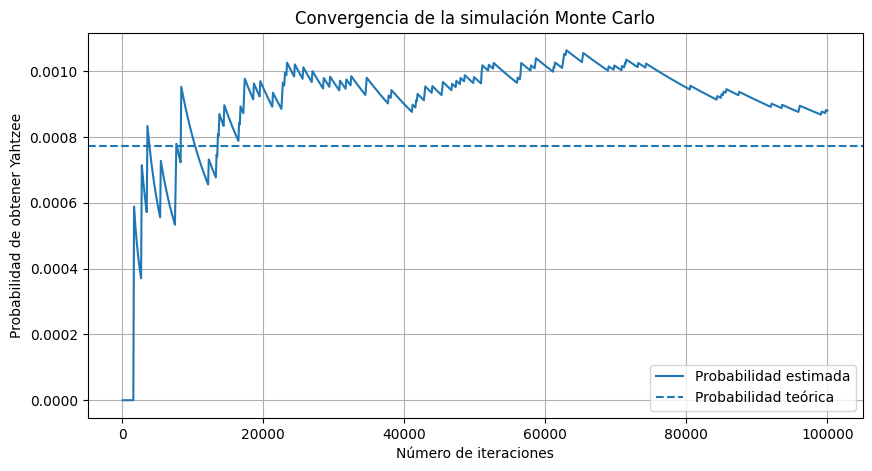

In [23]:
# Mejora del experimento anterior

import matplotlib.pyplot as plt
import random

iteraciones = 100000
exitos = 0
probabilidades = []

# Repetir el experimento y actualizar los éxitos
for i in range(1, iteraciones + 1):
    # Lanzar cinco dados al azar
    dados = [random.randint(1, 6) for j in range(5)]

    # Contar si se obtuvo Yahtzee
    if len(set(dados)) == 1:
        exitos += 1

    # Guardar la probabilidad estimada cada 100 iteraciones.
    if i % 100 == 0:
        probabilidades.append(exitos / i)

# Crear los valores del eje horizontal
cantidades = list(range(100, iteraciones + 1, 100))

# Crear la gráfica de convergencia
plt.figure(figsize=(10, 5))
plt.plot(cantidades, probabilidades, label="Probabilidad estimada")

# Añadir la probabilidad teórica como referencia
plt.axhline(1 / 1296, linestyle="--", label="Probabilidad teórica")

# Agregar titulos y nombres a los ejes
plt.xlabel("Número de iteraciones")
plt.ylabel("Probabilidad de obtener Yahtzee")
plt.title("Convergencia de la simulación Monte Carlo")

# Mostrar la laeyenda, la cuadrícula y la gráfica
plt.legend()
plt.grid(True)
plt.show()

In [24]:
import random

# Crear un dado con mayor probabilidad de sacar 6
def lanzar_dado_cargado():
    return random.choices(
        [1, 2, 3, 4, 5, 6],
        weights=[14, 14, 14, 14, 14, 30],
        k=1
    )[0]


def simular_dado_cargado(iteraciones):
    exitos = 0

    for i in range(iteraciones):
        dados = [lanzar_dado_cargado() for j in range(5)]

        # Verificar si los cinco dados son iguales
        if len(set(dados)) == 1:
            exitos += 1

    # Calcular la probabilidad estimada
    probabilidad = exitos / iteraciones

    return exitos, probabilidad


for cantidad in [10, 1000, 100000]:
    exitos, probabilidad = simular_dado_cargado(cantidad)

    print("Iteraciones:", cantidad)
    print("Yahtzees obtenidos:", exitos)
    print("Probabilidad estimada:", round(probabilidad * 100, 4), "%")
    print()

Iteraciones: 10
Yahtzees obtenidos: 0
Probabilidad estimada: 0.0 %

Iteraciones: 1000
Yahtzees obtenidos: 3
Probabilidad estimada: 0.3 %

Iteraciones: 100000
Yahtzees obtenidos: 248
Probabilidad estimada: 0.248 %



In [25]:
# Comparar las estrategías

import random
from collections import Counter

# Crear un dado con mayor probabilidad de sacar 6
def lanzar_dado_experimental(cargado=False):
    if cargado:
        return random.choices(
            [1, 2, 3, 4, 5, 6],
            weights=[14, 14, 14, 14, 14, 30],
            k=1
        )[0]

    return random.randint(1, 6)


def lanzar_cinco_experimentales(cargado=False):
    return [
        lanzar_dado_experimental(cargado)
        for i in range(5)
    ]


def experimento_estrategias(iteraciones, estrategia, cargado=False):
    exitos = 0

    for i in range(iteraciones):
        # Buscar una mano inicial con exactamente tres dados iguales
        while True:
            dados = lanzar_cinco_experimentales(cargado)
            conteo = Counter(dados)

            caras_tercia = [
                cara for cara, cantidad in conteo.items()
                if cantidad == 3
            ]

            if caras_tercia:
                cara_tercia = caras_tercia[0]
                break

        # Realizar dos lanzamientos adicionales
        for lanzamiento in range(2):
            if estrategia == "A":
                # Conservar los dados de la tercia original
                nuevos_dados = [
                    dado for dado in dados
                    if dado == cara_tercia
                ]

                while len(nuevos_dados) < 5:
                    nuevos_dados.append(
                        lanzar_dado_experimental(cargado)
                    )

                dados = nuevos_dados

            else:
                # Relanzar los cinco dados
                dados = lanzar_cinco_experimentales(cargado)

            if len(set(dados)) == 1:
                exitos += 1
                break

    return exitos, exitos / iteraciones


iteraciones = 100000

for cargado in [False, True]:
    if cargado:
        print("\n===== DADO CARGADO =====")
    else:
        print("\n===== DADO JUSTO =====")

    for estrategia in ["A", "B"]:
        exitos, probabilidad = experimento_estrategias(
            iteraciones, estrategia, cargado
        )

        if estrategia == "A":
            print("\nEstrategia A: conservar la tercia")
        else:
            print("\nEstrategia B: relanzar los cinco dados")

        print("Iteraciones:", iteraciones)
        print("Yahtzees obtenidos:", exitos)
        print(
            "Probabilidad estimada:",
            round(probabilidad * 100, 4),
            "%"
        )


===== DADO JUSTO =====

Estrategia A: conservar la tercia
Iteraciones: 100000
Yahtzees obtenidos: 9459
Probabilidad estimada: 9.459 %

Estrategia B: relanzar los cinco dados
Iteraciones: 100000
Yahtzees obtenidos: 163
Probabilidad estimada: 0.163 %

===== DADO CARGADO =====

Estrategia A: conservar la tercia
Iteraciones: 100000
Yahtzees obtenidos: 17777
Probabilidad estimada: 17.777 %

Estrategia B: relanzar los cinco dados
Iteraciones: 100000
Yahtzees obtenidos: 544
Probabilidad estimada: 0.544 %


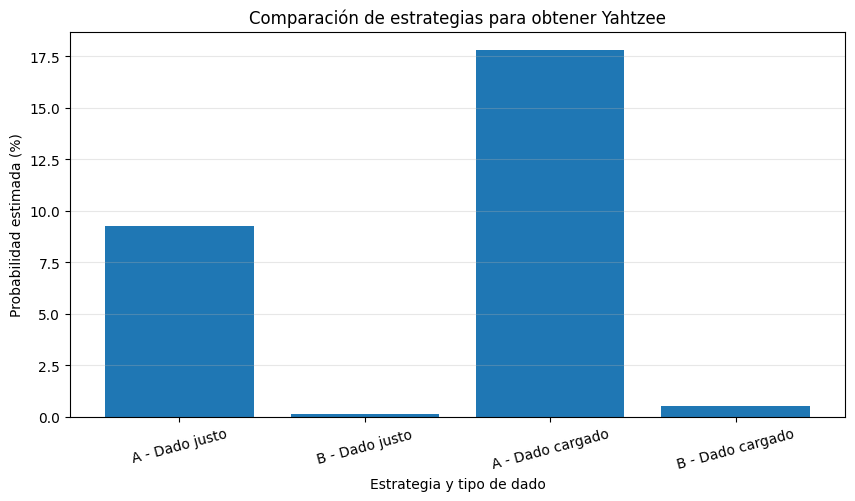

In [26]:
# Gráfica comparativa

import matplotlib.pyplot as plt

# Definir las estrategias que se van a comparar
estrategias = [
    "A - Dado justo",
    "B - Dado justo",
    "A - Dado cargado",
    "B - Dado cargado"
]

# Guardar las probabilidades obtenidas en cada estrategia
probabilidades = [9.272, 0.154, 17.788, 0.546]

plt.figure(figsize=(10, 5))
plt.bar(estrategias, probabilidades)

plt.title("Comparación de estrategias para obtener Yahtzee")
plt.xlabel("Estrategia y tipo de dado")
plt.ylabel("Probabilidad estimada (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [27]:
# Guardar resultados en una tabla

import pandas as pd

# Organizar los resultados de cada estrategia
resultados = {
    "Tipo de dado": [
        "Justo",
        "Justo",
        "Cargado",
        "Cargado"
    ],
    "Estrategia": [
        "Conservar la tercia",
        "Relanzar los cinco dados",
        "Conservar la tercia",
        "Relanzar los cinco dados"
    ],
    "Iteraciones": [
        100000,
        100000,
        100000,
        100000
    ],
    "Yahtzees obtenidos": [
        9272,
        154,
        17788,
        546
    ],
    "Probabilidad (%)": [
        9.272,
        0.154,
        17.788,
        0.546
    ]
}

# Convertir los resultados en una tabla
tabla_resultados = pd.DataFrame(resultados)

display(tabla_resultados)

,Tipo de dado,Estrategia,Iteraciones,Yahtzees obtenidos,Probabilidad (%)
0,Justo,Conservar la tercia,100000,9272,9.272
1,Justo,Relanzar los cinco dados,100000,154,0.154
2,Cargado,Conservar la tercia,100000,17788,17.788
3,Cargado,Relanzar los cinco dados,100000,546,0.546


In [28]:
# Probabilidad teorica de obtener Yahtzee en un lanzamiento

probabilidad_justo = 6 * (1 / 6) ** 5

probabilidad_cargado = (
    5 * (0.14 ** 5) + (0.30 ** 5)
)

print("VALIDACION DE LAS PROBABILIDADES")
print()
print(
    "Dado justo:",
    round(probabilidad_justo * 100, 4),
    "%"
)
print(
    "Dado cargado:",
    round(probabilidad_cargado * 100, 4),
    "%"
)

print()
print("RESULTADOS DE LAS SIMULACIONES")
print("Dado justo: 0.1 %")
print("Dado cargado: 0.26 %")

VALIDACION DE LAS PROBABILIDADES

Dado justo: 0.0772 %
Dado cargado: 0.2699 %

RESULTADOS DE LAS SIMULACIONES
Dado justo: 0.1 %
Dado cargado: 0.26 %


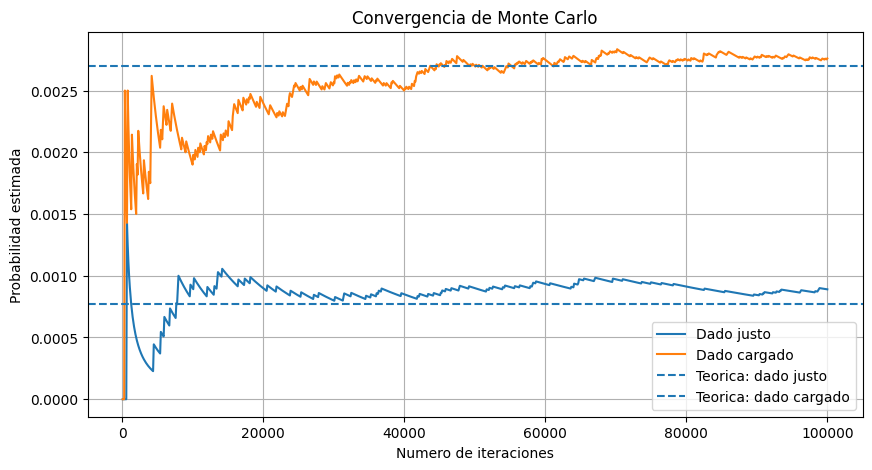

In [29]:
# Comprobar la convergencia con una gráfica más clara

import random
import matplotlib.pyplot as plt

iteraciones = 100000

# Iniciar los contadores de éxitos
exitos_justo = 0
exitos_cargado = 0

# Crear listas para guardar las probabilidades
probabilidades_justo = []
probabilidades_cargado = []
cantidades = []

# Repetir el experimento en cada iteración
for i in range(1, iteraciones + 1):
    dados_justos = [
        random.randint(1, 6) for j in range(5)
    ]

    dados_cargados = [
        random.choices(
            [1, 2, 3, 4, 5, 6],
            weights=[14, 14, 14, 14, 14, 30],
            k=1
        )[0]
        for j in range(5)
    ]

    if len(set(dados_justos)) == 1:
        exitos_justo += 1

    if len(set(dados_cargados)) == 1:
        exitos_cargado += 1

    # Guardar los resultados cada 100 iteraciones
    if i % 100 == 0:
        cantidades.append(i)
        probabilidades_justo.append(exitos_justo / i)
        probabilidades_cargado.append(exitos_cargado / i)

plt.figure(figsize=(10, 5))

plt.plot(
    cantidades,
    probabilidades_justo,
    label="Dado justo"
)

plt.plot(
    cantidades,
    probabilidades_cargado,
    label="Dado cargado"
)

plt.axhline(
    6 * (1 / 6) ** 5,
    linestyle="--",
    label="Teorica: dado justo"
)

plt.axhline(
    5 * (0.14 ** 5) + (0.30 ** 5),
    linestyle="--",
    label="Teorica: dado cargado"
)

plt.xlabel("Numero de iteraciones")
plt.ylabel("Probabilidad estimada")
plt.title("Convergencia de Monte Carlo")
plt.legend()
plt.grid(True)
plt.show()